In [24]:
%pip install --quiet red-dwarf[all]@git+https://github.com/polis-community/red-dwarf.git@main

Note: you may need to restart the kernel to use updated packages.


In [25]:
from reddwarf.data_loader import Loader
from reddwarf.utils.statements import process_statements
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [26]:


# You can also load from a Polis URL: Loader(polis_id="r2dfw8eambusb8buvecjt")
loader = Loader(filepaths=[
    "../../tests/fixtures/above-100-ptpts/votes.json",
    "../../tests/fixtures/above-100-ptpts/comments.json",
    "../../tests/fixtures/above-100-ptpts/conversation.json",
])

_, _, mod_out_statement_ids, meta_statement_ids = process_statements(
    statement_data=loader.comments_data
)

# Build a lookup for statement text
stmt_text = {}
for c in loader.comments_data:
    sid = c.get("tid", c.get("statement_id"))
    stmt_text[sid] = c.get("txt", "")

print(f"Loaded {len(loader.votes_data)} votes")

print(f"Statements: {len(loader.comments_data)} total, {len(mod_out_statement_ids)} moderated out")


print(loader.votes_data[0])

# nb of participants
list_of_ids_of_answer = [vote_data['participant_id'] for vote_data in loader.votes_data]
unique_id = np.unique(list_of_ids_of_answer)
nb_participants = len(unique_id)
print(nb_participants)



Loaded 5216 votes
Statements: 63 total, 7 moderated out
{'participant_id': 0, 'statement_id': 1, 'vote': 1, 'weight_x_32767': 0, 'modified': 1515620784141.0, 'conversation_id': '3ntrtcehas'}
267


In [27]:
conversation = pd.DataFrame(loader.votes_data)
print(conversation.head())
conversation_matrix = pd.crosstab(conversation['participant_id'], conversation['statement_id'], conversation['vote'], aggfunc='sum', dropna=False)

# how many values in the conversation matrix are nan
print(conversation_matrix.isna().sum().sum()/conversation_matrix.size)

# fill all the nan values with 0
conversation_matrix = conversation_matrix.fillna(0)

   participant_id  statement_id  vote  weight_x_32767      modified  \
0               0             1     1               0  1.515621e+12   
1               0             2     1               0  1.515621e+12   
2               0             3     1               0  1.515621e+12   
3               0             4     1               0  1.515621e+12   
4               0             5    -1               0  1.515621e+12   

  conversation_id  
0      3ntrtcehas  
1      3ntrtcehas  
2      3ntrtcehas  
3      3ntrtcehas  
4      3ntrtcehas  
0.6744069912609238


Average distance between first 10 participants: 5.055569862194534


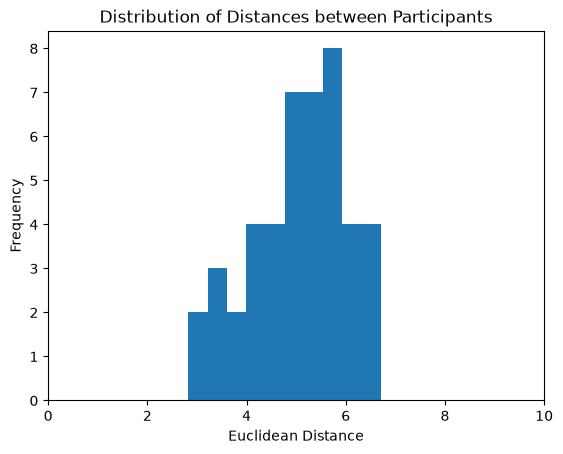

In [31]:
# test concentration euclidean distances

distance_list = []
for i in range(0, 10):
    for j in range(i+1, 10):
        distance_list.append(np.linalg.norm(conversation_matrix.iloc[i] - conversation_matrix.iloc[j]))


print(f"Average distance between first 10 participants: {np.mean(distance_list)}")

plt.hist(distance_list, bins=10)
plt.xlim(0, 10)
plt.xlabel("Euclidean Distance")
plt.ylabel("Frequency")
plt.title("Distribution of Distances between Participants")
plt.show()


C:\Users\pietr\AppData\Local\Temp\ipykernel_17540\2068213514.py:5: RuntimeWarning: invalid value encountered in scalar divide
  angle.append(np.arccos(np.dot(conversation_matrix.iloc[i], conversation_matrix.iloc[j]) / (np.linalg.norm(conversation_matrix.iloc[i]) * np.linalg.norm(conversation_matrix.iloc[j]))))


Average angle between first 10 participants: nan


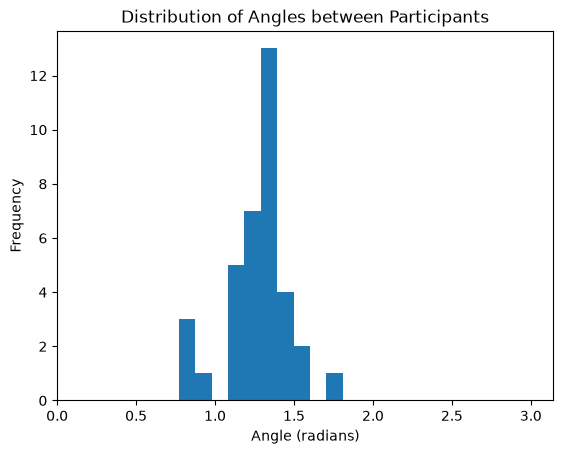

In [32]:
#test concentration of angles
angle = []
for i in range(0, 10):
    for j in range(i+1, 10):
        angle.append(np.arccos(np.dot(conversation_matrix.iloc[i], conversation_matrix.iloc[j]) / (np.linalg.norm(conversation_matrix.iloc[i]) * np.linalg.norm(conversation_matrix.iloc[j]))))
print(f"Average angle between first 10 participants: {np.mean(angle)}")

plt.hist(angle, bins=10)
plt.xlim(0, np.pi)
plt.xlabel("Angle (radians)")
plt.ylabel("Frequency")
plt.title("Distribution of Angles between Participants")
plt.show()
